# Verificación de la capa Gold — Iceberg

Comprobamos las dos tablas gold tras los ETL:
- `nessie.nyc.yellow_taxi_trips` (trip-level enriquecido)
- `nessie.nyc.pickup_demand_zone_hour` (agregado por zona × hora)

Para cada una validamos referencias Nessie, esquema, snapshots, particionado,
calidad de datos y consistencia con la capa silver. La auditoría va más allá
del audit gate del ETL: verifica conservación de filas (silver→gold), ausencia
de zonas NULL tras el join, coherencia de las columnas derivadas y, en el
agregado, conservación del total de pickups.

In [1]:
import re

from common.spark_factory import get_spark
from common import nessie_manager as nessie
from pyspark.sql.functions import (
    avg, col, count, max as spark_max, min as spark_min,
    month as spark_month, rand, stddev, sum as spark_sum, when,
    year as spark_year,
)
import pandas as pd
import matplotlib.pyplot as plt

spark = get_spark("verify-gold-iceberg")
nessie.set_spark_branch(spark, "main")
spark.version

26/05/17 19:59:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/05/17 20:00:01 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties
26/05/17 20:00:02 WARN S3ABlockOutputStream: Application invoked the Syncable API against stream writing to events/app-20260517200000-0013.inprogress. This is unsupported


'3.5.8'

## 1. Catálogo Nessie — Referencias y namespaces

In [2]:
# Todas las referencias relevantes para gold (main + tags + WAP branches residuales si los hay).
nessie.print_references(spark)

  * Branch bronze                                   8097a4dacf70
  * Branch main                                     76caa7201ce8
  * Branch silver                                   f5e12552937a
    Tag    bronze-taxi_zone_lookup-2026             8097a4dacf70
    Tag    bronze-yellow_taxi-2019                  80d9ac5e044b
    Tag    bronze-yellow_taxi-2020                  b66a4f1f6855
    Tag    bronze-yellow_taxi-2022                  8c5b8217b632
    Tag    bronze-yellow_taxi-2023                  9a8380e67e3d
    Tag    bronze-yellow_taxi-2025                  7962320e85ff
    Tag    gold-pickup_demand_zone_hour-2019        cf7fc38392d8
    Tag    gold-pickup_demand_zone_hour-2020        8765670c5dbf
    Tag    gold-pickup_demand_zone_hour-2022        1ff9734e0e44
    Tag    gold-pickup_demand_zone_hour-2023        d756abe3caf7
    Tag    gold-pickup_demand_zone_hour-2025        76caa7201ce8
    Tag    gold-yellow_taxi_trips-2019              25f7fa77f0e9
    Tag    gold-yellow_ta

> **Nota — alcance de 13 meses.** Entre las referencias aparecen los tags
> `review/silver-yellow_taxi-2025-02` y `review/silver-yellow_taxi-2025-03`:
> febrero y marzo de 2025 quedaron en cuarentena en la capa **silver** (superaron
> el umbral `MAX_DROP_RATIO = 0.20` del audit gate), nunca se mergearon a
> `silver` y por tanto tampoco llegan a gold. De ahí que gold contenga 13 meses
> —Q1 completo de 2019, 2020, 2022 y 2023, más solo enero de 2025— y no 15. No
> es un hueco de ingesta: es el comportamiento esperado «audit falla →
> cuarentena + continuar».

In [3]:
# Namespaces y tablas en main
spark.sql("SHOW NAMESPACES IN nessie").show()
spark.sql("SHOW TABLES IN nessie.nyc").show(truncate=False)

+---------+
|namespace|
+---------+
|      nyc|
+---------+

+---------+-----------------------+-----------+
|namespace|tableName              |isTemporary|
+---------+-----------------------+-----------+
|nyc      |pickup_demand_zone_hour|false      |
|nyc      |yellow_taxi_trips      |false      |
+---------+-----------------------+-----------+



## 2. yellow_taxi_trips — Propiedades y esquema

In [4]:
spark.sql("DESCRIBE TABLE EXTENDED nessie.nyc.yellow_taxi_trips").show(200, truncate=False)

+-----------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|col_name                     |data_type                                                                                                                                                                                                                                                                                                     |comment|
+-----------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [5]:
# Esquema con tipos
spark.table("nessie.nyc.yellow_taxi_trips").printSchema()

root
 |-- pickup_datetime: timestamp_ntz (nullable = false)
 |-- dropoff_datetime: timestamp_ntz (nullable = false)
 |-- pickup_year: integer (nullable = false)
 |-- pickup_month: integer (nullable = false)
 |-- pickup_week: integer (nullable = false)
 |-- pickup_dow: integer (nullable = false)
 |-- pickup_hour: integer (nullable = false)
 |-- trip_duration_minutes: double (nullable = false)
 |-- pu_location_id: integer (nullable = false)
 |-- pu_borough: string (nullable = false)
 |-- pu_zone: string (nullable = false)
 |-- pu_service_zone: string (nullable = true)
 |-- do_location_id: integer (nullable = false)
 |-- do_borough: string (nullable = false)
 |-- do_zone: string (nullable = false)
 |-- do_service_zone: string (nullable = true)
 |-- vendor_id: integer (nullable = false)
 |-- ratecode_id: integer (nullable = false)
 |-- payment_type: long (nullable = false)
 |-- store_and_fwd_flag: string (nullable = false)
 |-- passenger_count: double (nullable = false)
 |-- trip_distance:

## 3. yellow_taxi_trips — Snapshots e historial

In [6]:
spark.sql("""
    SELECT committed_at, snapshot_id, parent_id, operation,
           summary['added-records'] AS added_records,
           summary['total-records'] AS total_records
    FROM nessie.nyc.yellow_taxi_trips.snapshots
    ORDER BY committed_at
""").show(truncate=False)

+-----------------------+-------------------+-------------------+---------+-------------+-------------+
|committed_at           |snapshot_id        |parent_id          |operation|added_records|total_records|
+-----------------------+-------------------+-------------------+---------+-------------+-------------+
|2026-05-17 18:56:21.59 |4183937674055404669|NULL               |append   |7460359      |7460359      |
|2026-05-17 18:58:02.348|4807565585093015510|4183937674055404669|append   |6833264      |14293623     |
|2026-05-17 18:59:55.126|1134714233183123806|4807565585093015510|append   |7633194      |21926817     |
|2026-05-17 19:01:32.089|3976180483038499018|1134714233183123806|append   |6201962      |28128779     |
|2026-05-17 19:03:09.421|5508805907901011165|3976180483038499018|append   |6103376      |34232155     |
|2026-05-17 19:04:02.821|196937338156990780 |5508805907901011165|append   |2893173      |37125328     |
|2026-05-17 19:04:51.226|5707752472428081203|196937338156990780 

## 3b. Crecimiento por tag anual — ambas tablas gold

Un tag por año (`gold-{tabla}-{YYYY}`) marca el snapshot publicado tras el
último mes mergeado de ese año, para cada una de las dos tablas gold
(`yellow_taxi_trips` y `pickup_demand_zone_hour`). Contamos filas a la altura
de cada tag.

In [7]:
TABLES = [
    ("yellow_taxi_trips", "nessie.nyc.yellow_taxi_trips"),
    ("pickup_demand_zone_hour", "nessie.nyc.pickup_demand_zone_hour"),
]

refs = nessie.list_references(spark)
tag_pattern = re.compile(r"gold-(?P<table>[a-z_]+)-(?P<year>\d{4})")
yearly_tags = {tbl: [] for tbl, _ in TABLES}
for r in refs:
    # Nessie devuelve refType en mixed-case ("Tag" / "Branch"), no en mayusculas.
    # Comparar contra "TAG" en exacto descartaba todos los tags y dejaba rows=[].
    if (r["refType"] or "").upper() != "TAG":
        continue
    m = tag_pattern.fullmatch(r["name"])
    if m and m.group("table") in yearly_tags:
        yearly_tags[m.group("table")].append(r["name"])
for tbl in yearly_tags:
    yearly_tags[tbl].sort()

rows = []
for tbl, fqn in TABLES:
    for tag in yearly_tags[tbl]:
        nessie.set_spark_branch(spark, tag)
        n = spark.table(fqn).count()
        rows.append((tbl, tag, n))
nessie.set_spark_branch(spark, "main")

if not rows:
    print("No yearly gold tags found. Run the gold pipelines first.")
else:
    growth_df = spark.createDataFrame(rows, ["table", "tag", "rows"])
    growth_df.orderBy("table", "tag").show(truncate=False)

+-----------------------+---------------------------------+--------+
|table                  |tag                              |rows    |
+-----------------------+---------------------------------+--------+
|pickup_demand_zone_hour|gold-pickup_demand_zone_hour-2019|300910  |
|pickup_demand_zone_hour|gold-pickup_demand_zone_hour-2020|534144  |
|pickup_demand_zone_hour|gold-pickup_demand_zone_hour-2022|730127  |
|pickup_demand_zone_hour|gold-pickup_demand_zone_hour-2023|934488  |
|pickup_demand_zone_hour|gold-pickup_demand_zone_hour-2025|1010343 |
|yellow_taxi_trips      |gold-yellow_taxi_trips-2019      |21926817|
|yellow_taxi_trips      |gold-yellow_taxi_trips-2020      |37125328|
|yellow_taxi_trips      |gold-yellow_taxi_trips-2022      |45665180|
|yellow_taxi_trips      |gold-yellow_taxi_trips-2023      |54573946|
|yellow_taxi_trips      |gold-yellow_taxi_trips-2025      |57423106|
+-----------------------+---------------------------------+--------+



## 4. yellow_taxi_trips — Particionado y ficheros

In [8]:
# Particiones (hidden partitioning by month(pickup_datetime))
spark.sql("""
    SELECT partition, record_count, file_count
    FROM nessie.nyc.yellow_taxi_trips.partitions
    ORDER BY partition
""").show(50, truncate=False)

+---------+------------+----------+
|partition|record_count|file_count|
+---------+------------+----------+
|{588}    |7460359     |1         |
|{589}    |6833264     |1         |
|{590}    |7633194     |1         |
|{600}    |6201962     |1         |
|{601}    |6103376     |1         |
|{602}    |2893173     |1         |
|{624}    |2326489     |1         |
|{625}    |2798864     |1         |
|{626}    |3414499     |1         |
|{636}    |2917644     |1         |
|{637}    |2764185     |1         |
|{638}    |3226937     |1         |
|{660}    |2849160     |1         |
+---------+------------+----------+



In [9]:
# Ficheros físicos — conteo, filas y tamaño total en una sola pasada.
stats = spark.sql(
    "SELECT * FROM nessie.nyc.yellow_taxi_trips.files"
).agg(
    count("*").alias("file_count"),
    spark_sum("file_size_in_bytes").alias("total_bytes"),
    spark_sum("record_count").alias("total_rows"),
).first()
print(f"Files: {stats['file_count']}")
print(f"Rows : {stats['total_rows']:,}")
print(f"Size : {stats['total_bytes']/(1024**2):,.1f} MiB")

26/05/17 20:00:15 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Files: 13
Rows : 57,423,106
Size : 1,003.2 MiB


## 5. yellow_taxi_trips — Auditoría de calidad

Los gates del ETL ya filtran lo más grueso, pero re-verificamos sobre la tabla
publicada. Lo que comprobamos:

- **Zonas no nulas**: silver garantiza PU/DO en `[1, 265]` y la tabla de zonas
  los cubre todos → tras el `LEFT JOIN`, ninguna columna `pu_borough` /
  `do_borough` debe ser NULL.
- **Duración positiva**: silver enforza `pickup < dropoff` →
  `trip_duration_minutes > 0` siempre.
- **Coherencia de las columnas derivadas**: `pickup_year` debe coincidir con
  `year(pickup_datetime)`, idem mes.

In [10]:
# Auditoría en una sola pasada (igual patrón que el ETL y el silver verify).
trips = spark.table("nessie.nyc.yellow_taxi_trips")

checks = {
    "null_pu_borough":       col("pu_borough").isNull(),
    "null_do_borough":       col("do_borough").isNull(),
    "non_positive_duration": col("trip_duration_minutes") <= 0,
    "pickup_year_mismatch":  spark_year("pickup_datetime") != col("pickup_year"),
    "pickup_month_mismatch": spark_month("pickup_datetime") != col("pickup_month"),
}

audit = trips.agg(
    count("*").alias("total_rows"),
    *[spark_sum(when(cond, 1).otherwise(0)).alias(label)
      for label, cond in checks.items()],
).first().asDict()

total_rows = audit.pop("total_rows")
print(f"Total rows: {total_rows:,}\n")

width = max(len(k) for k in audit)
for label, n in audit.items():
    flag = "OK" if n == 0 else "FAIL"
    print(f"  [{flag}] {label.ljust(width)} : {n}")

assert all(n == 0 for n in audit.values()), "Quality audit failed"
print("\nAll quality assertions OK")

Total rows: 57,423,106

  [OK] null_pu_borough       : 0
  [OK] null_do_borough       : 0
  [OK] non_positive_duration : 0
  [OK] pickup_year_mismatch  : 0
  [OK] pickup_month_mismatch : 0

All quality assertions OK


## 6. yellow_taxi_trips — Silver vs Gold (conservación de filas)

El ETL de gold hace un `LEFT JOIN` 1:1 con la tabla de zonas. Las filas de gold
deben coincidir exactamente con las de silver mes a mes. Si hay desviación,
señala un fallo en el join o filas perdidas en la transformación.

In [11]:
# Conteo silver por (year, month) — se reutiliza en la sección 10.
nessie.set_spark_branch(spark, "silver")
silver_per_month = (
    spark.table("nessie.nyc.yellow_taxi")
    .groupBy(
        spark_year("tpep_pickup_datetime").alias("year"),
        spark_month("tpep_pickup_datetime").alias("month"),
    )
    .agg(count("*").alias("silver_count"))
    .orderBy("year", "month")
    .toPandas()
)
nessie.set_spark_branch(spark, "main")

gold_counts = (
    spark.table("nessie.nyc.yellow_taxi_trips")
    .groupBy(col("pickup_year").alias("year"), col("pickup_month").alias("month"))
    .agg(count("*").alias("gold_count"))
    .orderBy("year", "month")
    .toPandas()
)

cmp = silver_per_month.merge(gold_counts, on=["year", "month"], how="outer").fillna(0)
cmp["diff"] = cmp["gold_count"] - cmp["silver_count"]
print(cmp.to_string(index=False))

 year  month  silver_count  gold_count  diff
 2019      1       7460359     7460359     0
 2019      2       6833264     6833264     0
 2019      3       7633194     7633194     0
 2020      1       6201962     6201962     0
 2020      2       6103376     6103376     0
 2020      3       2893173     2893173     0
 2022      1       2326489     2326489     0
 2022      2       2798864     2798864     0
 2022      3       3414499     3414499     0
 2023      1       2917644     2917644     0
 2023      2       2764185     2764185     0
 2023      3       3226937     3226937     0
 2025      1       2849160     2849160     0


In [12]:
mismatched = cmp[cmp["diff"] != 0]
if mismatched.empty:
    print("Silver vs Gold: identical row counts in every month.")
else:
    print("MISMATCH detected — investigate before consuming gold:")
    print(mismatched.to_string(index=False))

Silver vs Gold: identical row counts in every month.


## 7. yellow_taxi_trips — Muestra de datos

In [13]:
# Muestra representativa: orderBy(rand(seed)) baraja la tabla entera para que
# las filas salgan de meses y zonas distintos. Un show(5) sin barajar devuelve
# siempre las primeras filas de la primera particion escaneada (un unico mes).
spark.table("nessie.nyc.yellow_taxi_trips").orderBy(rand(42)).show(5, truncate=False)

+-------------------+-------------------+-----------+------------+-----------+----------+-----------+---------------------+--------------+----------+-------------------+---------------+--------------+----------+----------------------------+---------------+---------+-----------+------------+------------------+---------------+-------------+-----------+----------+------------+-------+-----+---------------------+--------------------+-----------+------------------+------------+
|pickup_datetime    |dropoff_datetime   |pickup_year|pickup_month|pickup_week|pickup_dow|pickup_hour|trip_duration_minutes|pu_location_id|pu_borough|pu_zone            |pu_service_zone|do_location_id|do_borough|do_zone                     |do_service_zone|vendor_id|ratecode_id|payment_type|store_and_fwd_flag|passenger_count|trip_distance|fare_amount|tip_amount|tolls_amount|mta_tax|extra|improvement_surcharge|congestion_surcharge|airport_fee|cbd_congestion_fee|total_amount|
+-------------------+-------------------+---

## 8. pickup_demand_zone_hour — Propiedades y esquema

In [14]:
spark.sql("DESCRIBE TABLE EXTENDED nessie.nyc.pickup_demand_zone_hour").show(200, truncate=False)

+-----------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|col_name                     |data_type                                                                                                                                                                                                                                                                                                    |comment|
+-----------------------------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [15]:
spark.table("nessie.nyc.pickup_demand_zone_hour").printSchema()

root
 |-- hour_bucket: timestamp_ntz (nullable = false)
 |-- pu_location_id: integer (nullable = false)
 |-- pu_borough: string (nullable = false)
 |-- pu_zone: string (nullable = false)
 |-- pu_service_zone: string (nullable = true)
 |-- hour_year: integer (nullable = false)
 |-- hour_month: integer (nullable = false)
 |-- hour_week: integer (nullable = false)
 |-- hour_dow: integer (nullable = false)
 |-- hour_of_day: integer (nullable = false)
 |-- n_pickups: long (nullable = false)
 |-- total_revenue: double (nullable = false)
 |-- avg_fare: double (nullable = false)
 |-- avg_tip: double (nullable = false)
 |-- avg_distance: double (nullable = false)
 |-- avg_passengers: double (nullable = false)



## 9. pickup_demand_zone_hour — Snapshots y particionado

In [16]:
spark.sql("""
    SELECT committed_at, snapshot_id, operation,
           summary['added-records'] AS added_records,
           summary['total-records'] AS total_records
    FROM nessie.nyc.pickup_demand_zone_hour.snapshots
    ORDER BY committed_at
""").show(truncate=False)

+-----------------------+-------------------+---------+-------------+-------------+
|committed_at           |snapshot_id        |operation|added_records|total_records|
+-----------------------+-------------------+---------+-------------+-------------+
|2026-05-17 19:13:23.007|4138627030388876487|append   |102101       |102101       |
|2026-05-17 19:13:53.086|4167435545889330666|append   |94257        |196358       |
|2026-05-17 19:14:18.218|4944992927468195622|append   |104552       |300910       |
|2026-05-17 19:14:38.712|4116444336753042372|append   |86158        |387068       |
|2026-05-17 19:15:01.071|5989692695091170760|append   |79782        |466850       |
|2026-05-17 19:15:24.616|6282657536203074835|append   |67294        |534144       |
|2026-05-17 19:15:47.798|3953806777734843604|append   |63804        |597948       |
|2026-05-17 19:16:11.096|8303541765562210501|append   |61878        |659826       |
|2026-05-17 19:16:33.208|3035396161048622058|append   |70301        |730127 

In [17]:
spark.sql("""
    SELECT partition, record_count, file_count
    FROM nessie.nyc.pickup_demand_zone_hour.partitions
    ORDER BY partition
""").show(50, truncate=False)

+---------+------------+----------+
|partition|record_count|file_count|
+---------+------------+----------+
|{588}    |102101      |1         |
|{589}    |94257       |1         |
|{590}    |104552      |1         |
|{600}    |86158       |1         |
|{601}    |79782       |1         |
|{602}    |67294       |1         |
|{624}    |63804       |1         |
|{625}    |61878       |1         |
|{626}    |70301       |1         |
|{636}    |69528       |1         |
|{637}    |62732       |1         |
|{638}    |72101       |1         |
|{660}    |75855       |1         |
+---------+------------+----------+



## 10. pickup_demand_zone_hour — Auditoría: conservación de pickups

`sum(n_pickups)` mes a mes debe igualar el conteo de silver para ese mes —
todas las filas de silver tienen que estar contabilizadas en algún grupo
`(pu_location_id, hour_bucket)`. Si no, hay agregación con pérdida o filtro
indebido.

In [18]:
# silver_per_month ya calculado en la sección 6 — lo reutilizamos aquí.
demand_per_month = (
    spark.table("nessie.nyc.pickup_demand_zone_hour")
    .groupBy(col("hour_year").alias("year"), col("hour_month").alias("month"))
    .agg(spark_sum("n_pickups").alias("gold_pickups"))
    .orderBy("year", "month")
    .toPandas()
)

conserv = silver_per_month.merge(demand_per_month, on=["year", "month"], how="outer").fillna(0)
conserv["diff"] = conserv["gold_pickups"] - conserv["silver_count"]
print(conserv.to_string(index=False))

 year  month  silver_count  gold_pickups  diff
 2019      1       7460359       7460359     0
 2019      2       6833264       6833264     0
 2019      3       7633194       7633194     0
 2020      1       6201962       6201962     0
 2020      2       6103376       6103376     0
 2020      3       2893173       2893173     0
 2022      1       2326489       2326489     0
 2022      2       2798864       2798864     0
 2022      3       3414499       3414499     0
 2023      1       2917644       2917644     0
 2023      2       2764185       2764185     0
 2023      3       3226937       3226937     0
 2025      1       2849160       2849160     0


In [19]:
mismatched = conserv[conserv["diff"] != 0]
if mismatched.empty:
    print("Silver vs Gold: total pickups conserved in every month.")
else:
    print("CONSERVATION VIOLATION — pickups not conserved in aggregation:")
    print(mismatched.to_string(index=False))

Silver vs Gold: total pickups conserved in every month.


## 11. pickup_demand_zone_hour — Calidad y distribución

In [20]:
# Auditoría + distribución de n_pickups en una sola pasada.
demand = spark.table("nessie.nyc.pickup_demand_zone_hour")

stats = demand.agg(
    count("*").alias("total_groups"),
    spark_sum(when(col("pu_borough").isNull(), 1).otherwise(0)).alias("null_zone"),
    spark_min("n_pickups").alias("min_pickups"),
    spark_max("n_pickups").alias("max_pickups"),
    avg("n_pickups").alias("avg_pickups"),
    stddev("n_pickups").alias("stddev_pickups"),
).first()

print(f"Total (zone, hour) groups: {stats['total_groups']:,}")
print(f"NULL pu_borough: {stats['null_zone']}")
assert stats["null_zone"] == 0, "Zone join introduced NULLs in demand table"

print("\nn_pickups distribution:")
print(f"  min   : {stats['min_pickups']}")
print(f"  max   : {stats['max_pickups']}")
print(f"  mean  : {stats['avg_pickups']:.2f}")
print(f"  stddev: {stats['stddev_pickups']:.2f}")

Total (zone, hour) groups: 1,010,343
NULL pu_borough: 0

n_pickups distribution:
  min   : 1
  max   : 1394
  mean  : 56.84
  stddev: 109.01


In [21]:
# Top 10 zonas por pickups totales
top_zones = (
    demand.groupBy("pu_location_id", "pu_borough", "pu_zone")
    .agg(spark_sum("n_pickups").alias("total_pickups"))
    .orderBy(col("total_pickups").desc())
    .limit(10)
)
top_zones.show(truncate=False)

+--------------+----------+----------------------------+-------------+
|pu_location_id|pu_borough|pu_zone                     |total_pickups|
+--------------+----------+----------------------------+-------------+
|237           |Manhattan |Upper East Side South       |2578972      |
|161           |Manhattan |Midtown Center              |2469869      |
|236           |Manhattan |Upper East Side North       |2416986      |
|162           |Manhattan |Midtown East                |2062573      |
|186           |Manhattan |Penn Station/Madison Sq West|2008912      |
|132           |Queens    |JFK Airport                 |1996397      |
|230           |Manhattan |Times Sq/Theatre District   |1967676      |
|142           |Manhattan |Lincoln Square East         |1789992      |
|170           |Manhattan |Murray Hill                 |1759846      |
|48            |Manhattan |Clinton East                |1751634      |
+--------------+----------+----------------------------+-------------+



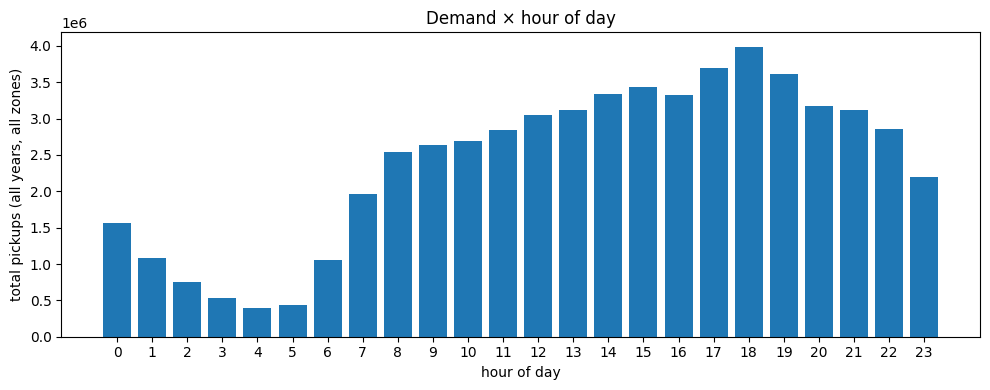

In [22]:
# Patrón demand × hour-of-day: ¿el pico está donde esperamos?
hourly = (
    demand.groupBy("hour_of_day")
    .agg(spark_sum("n_pickups").alias("total_pickups"))
    .orderBy("hour_of_day")
    .toPandas()
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hourly["hour_of_day"], hourly["total_pickups"])
ax.set_xlabel("hour of day")
ax.set_ylabel("total pickups (all years, all zones)")
ax.set_title("Demand × hour of day")
ax.set_xticks(range(0, 24))
plt.tight_layout()

## 12. Conclusiones

La capa gold publicada en `main` pasa todas las verificaciones definidas en este notebook sobre los 13 meses ingeridos (Q1 de 2019, 2020, 2022, 2023 y enero de 2025):

- **Alcance de los datos (sección 1)**. Gold cubre 13 meses, no 15: febrero y marzo de 2025 quedaron en cuarentena en silver (tags `review/silver-yellow_taxi-2025-02` y `-03`, por superar el umbral `MAX_DROP_RATIO = 0.20`) y no se propagan a gold. El recorte es el comportamiento esperado del audit gate, no un fallo de ingesta.
- **Conservación de filas silver → gold (sección 6)**. `yellow_taxi_trips` tiene exactamente las mismas filas que `silver.yellow_taxi` en cada uno de los 13 meses (`diff = 0` en toda la tabla, 57.423.106 filas en total). El `LEFT JOIN` con la tabla de zonas no introduce duplicados ni pérdidas — los IDs PU/DO de silver están todos cubiertos por `silver.taxi_zone_lookup`.
- **Conservación de pickups en el agregado (sección 10)**. `sum(n_pickups)` de `pickup_demand_zone_hour` iguala al conteo de silver en los 13 meses (`diff = 0`). El group-by por `(pu_location_id, hour_bucket)` no descarta filas: 1.010.343 grupos contabilizan los 57.423.106 viajes.
- **Zonas NULL (secciones 5 y 11)**. Cero filas con `pu_borough` o `do_borough` NULL en `yellow_taxi_trips`, y cero `pu_borough` NULL en `pickup_demand_zone_hour`. El audit gate del ETL ya lo garantizaba; la tabla publicada lo confirma.
- **Coherencia de las columnas derivadas (sección 5)**. `pickup_year` y `pickup_month` coinciden con `year/month(pickup_datetime)` en todas las filas, y `trip_duration_minutes > 0` siempre. Esto último no es trivial: gold calcula la duración como `(unix_timestamp(dropoff) - unix_timestamp(pickup)) / 60`, que trunca a segundos; el hecho de que ninguna fila salga con duración 0 indica que en estos 13 meses no hay viajes sub-segundo que silver haya dejado pasar.
- **Particionado razonable (secciones 4 y 9)**. Iceberg ha creado 13 particiones mensuales en cada tabla — una por mes ingerido, sin fragmentación interna (1 fichero por partición). En `yellow_taxi_trips` los ficheros pesan ~77 MiB de media (1.003 MiB / 13), tamaño cómodo para escaneo por mes. El particionado `months(...)` y la naturaleza single-writer de los ETL explican esta distribución limpia.
- **Patrón horario plausible (sección 11)**. El histograma `Demand × hour of day` reproduce la forma esperada de NYC: valle nocturno (~04:00–05:00) y pico de tarde (~18:00–19:00). El top-10 de zonas con más pickups está dominado por Manhattan (Upper East Side South / North, Midtown Center / East, Times Square, Penn Station) más JFK Airport — coherente con los puntos de mayor densidad de demanda en el dataset.

La capa gold queda lista para consumo por las pipelines de ML (`src/ml/`), que leen exclusivamente de `nessie.nyc.*` en `main`.